# Avance de investigacion: Front-End Convolucional 1D en GPU vs. Extracción Manual Log-Mel en BC-ResNet-1

## RQ

¿En qué medida la sustitución de la extracción artesanal de espectrogramas Log-Mel en CPU por un front-end convolucional 1D diferenciable sobre audio crudo altera la capacidad de discriminación fonética, la robustez paramétrica y el tiempo de entrenamiento de BC-ResNet-1 sobre Google Speech Commands v2?

## Hipotesis


La sustitución del extractor manual de espectrogramas Log-Mel en CPU por un front-end convolucional 1D aprendible directamente sobre audio crudo de 16 kHz ( K = 480, S=160, C=40) reducirá el tiempo de reloj por época de entrenamiento en al menos un 20% sobre GPU Tesla T4 (incrementando el throughput en más de un 25%), alcanzando una exactitud Top-1 en Google Speech Commands v2 que difiere en menos de 1,5 puntos porcentuales respecto al baseline del 96,00% en condiciones limpias, debido a que el descenso de gradiente estocástico sintoniza los núcleos temporales en bancos de filtros pasabanda que preservan el contraste formántico necesario para alimentar los bloques de broadcasting residual sin depender de transformaciones de Fourier prefijadas.

configuracion del entorno:

In [1]:
!nvidia-smi

Sat Nov  7 16:44:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
if not os.path.exists("bcresnet"):
    !git clone https://github.com/Qualcomm-AI-research/bcresnet.git
%cd bcresnet

Cloning into 'bcresnet'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 13 (delta 1), reused 0 (delta 0), pack-reused 7 (from 1)
Receiving objects: 100% (13/13), 231.00 KiB | 19.25 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/bcresnet


In [3]:
!pip install -q torchaudio scikit-learn seaborn matplotlib soundfile

In [4]:
from google.colab import drive
drive.mount('/content/drive')
BACKUP_DIR = "/content/drive/MyDrive/Avance_IPD440"
os.makedirs(BACKUP_DIR, exist_ok=True)
print(f"directorio de respaldo configurado en: {BACKUP_DIR}")

Mounted at /content/drive
directorio de respaldo configurado en: /content/drive/MyDrive/Avance_IPD440


In [6]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"semilla fijada en {SEED}. Dispositivo asignado: {device}")

semilla fijada en 42. Dispositivo asignado: cuda:0


descarga y preparacion del dataset:

In [7]:
import sys
import main

# configurar argumentos
sys.argv = ['main.py', '--ver', '2', '--tau', '1', '--gpu', '0', '--download']

# Instanciar Trainer: descarga, extrae y particiona las 12 clases sin entrenar
print("Descargando y preparando Google Speech Commands v2...")
trainer_setup = main.Trainer()

print(" Datos preparados y particionados exitosamente en ./data/speech_commands_v0.02")

Se truncaron las últimas líneas 5000 del resultado de transmisión.
Copied ./data/speech_commands_v0.02_split/test/bird/80c45ed6_nohash_0.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_80c45ed6_nohash_0.wav
Copied ./data/speech_commands_v0.02_split/test/bird/ca48dc76_nohash_1.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_ca48dc76_nohash_1.wav
Copied ./data/speech_commands_v0.02_split/test/bird/37fc5d97_nohash_0.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_37fc5d97_nohash_0.wav
Copied ./data/speech_commands_v0.02_split/test/bird/a60a09cf_nohash_0.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_a60a09cf_nohash_0.wav
Copied ./data/speech_commands_v0.02_split/test/bird/c7dc7278_nohash_0.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_c7dc7278_nohash_0.wav
Copied ./data/speech_commands_v0.02_split/test/bird/85d2ac4b_nohash_1.wav to ./data/speech_commands_v0.02/test_12class/_unknown_/bird_85d2ac4b_nohash_1.w

### construccion del propuesto:


Sustituye el preprocesamiento artesanal y estático de Fourier (STFT y banco de filtros Log-Mel rígidos en CPU) por una capa convolucional 1D que opera directamente sobre la onda de audio crudo en GPU.


el modelo recibe la señal acústica de entrada con dimensiones $[B, 1, 16000]$, emula mediante convolución temporal una ventana de $30\text{ ms}$ con salto de $10\text{ ms}$, calcula la energía logarítmica normalizada y genera internamente un tensor de rasgos espectro-temporales de $[B, 1, 40, 101]$. Dicho tensor alimenta directamente a los 12 bloques residuales canónicos de BC-ResNet-1 sin modificar su topología interna, verificando al final la coherencia dimensional de salida y el conteo de parámetros entrenables.

In [8]:
import torch
import torch.nn as nn
from bcresnet import BCResNets

class BCResNetRaw(nn.Module):
    def __init__(self, tau: float = 1.0):
        super().__init__()
        # front convolucional 1D
        # K=480 (30 ms a 16 kHz), S=160 (salto 10 ms), Padding=240 para preservar W=101
        self.front_end = nn.Conv1d(
            in_channels=1,
            out_channels=40,
            kernel_size=480,
            stride=160,
            padding=240,
            bias=False
        )
        self.front_norm = nn.BatchNorm1d(40)

        #instanciamos el resto de la arquitecutra original
        self.backbone = BCResNets(int(tau * 8))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        #entrada: [B, 1, 16000] (audio crudo)

        #Convolución temporal en GPU
        feat = self.front_end(x)  #out: [B, 40, 101]

        #estimación de energia logaritmica
        feat = torch.log(feat.pow(2) + 1e-6) #pot cuadratica instantanea de senal filtada
        feat = self.front_norm(feat) #norm de energia a traves de lotes de entrenamiento

        # add dimensión de canal monocanal [B, 1, 40, 101]
        feat = feat.unsqueeze(1)

        #propagacion por los bloques residuales originales de bcresnet1
        logits = self.backbone(feat)
        return logits

# prueba de dimensiones y conteo de parámetros
test_model = BCResNetRaw(tau=1.0).to(device)
dummy_input = torch.randn(2, 1, 16000, device=device)
dummy_output = test_model(dummy_input)

total_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
print(f"shape de salida de prueba: {dummy_output.shape} (esperado: [2, 12])")
print(f"parametros entrenables totales: {total_params:,} (Baseline: 9,510 | Front-End: 19,280)")

shape de salida de prueba: torch.Size([2, 12]) (esperado: [2, 12])
parametros entrenables totales: 28,512 (Baseline: 9,510 | Front-End: 19,280)


entrenamiento del modelo propuesto:

In [11]:
import time
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from tqdm import tqdm
from utils import Padding, SpeechCommand

#config DataLoaders(sin Log-Mel)
base_dir = "./data/speech_commands_v0.02"
transform = transforms.Compose([Padding()])

train_dataset = SpeechCommand(f"{base_dir}/train_12class", 2, transform=transform)
valid_dataset = SpeechCommand(f"{base_dir}/valid_12class", 2, transform=transform)
test_dataset  = SpeechCommand(f"{base_dir}/test_12class", 2, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=100, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=100, shuffle=False, num_workers=2, pin_memory=True)

#instanciar modelo y optimizador
model_raw = BCResNetRaw(tau=1.0).to(device)
total_epoch = 40
warmup_epoch = 5
init_lr = 0.1
optimizer = torch.optim.SGD(model_raw.parameters(), lr=0.0, momentum=0.9, weight_decay=1e-3)

n_step_warmup = len(train_loader) * warmup_epoch
total_iter = len(train_loader) * total_epoch
iterations = 0
best_valid_acc = 0.0
history = []

print(f"Iniciando entrenamiento con Raw Audio ({total_epoch} epocas)...")

for epoch in range(total_epoch):
    model_raw.train()
    start_time = time.time()
    total_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in tqdm(train_loader, desc=f"epoca {epoch+1}/{total_epoch}"):
        iterations += 1
        #scheduler: Warmup lineal + Cos Annealing
        if iterations < n_step_warmup:
            lr = init_lr * iterations / n_step_warmup
        else:
            lr = 0.5 * init_lr * (1 + np.cos(np.pi * (iterations - n_step_warmup) / (total_iter - n_step_warmup)))
        for p_group in optimizer.param_groups:
            p_group["lr"] = lr

        # Asegurar tensor 3D
        inputs = inputs.to(device, non_blocking=True)
        if inputs.ndim == 2:
            inputs = inputs.unsqueeze(1)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model_raw(inputs)
        loss = F.cross_entropy(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        correct_train += (outputs.argmax(dim=-1) == labels).sum().item()
        total_train += len(labels)

    epoch_duration = time.time() - start_time
    throughput = total_train / epoch_duration
    train_acc = (correct_train / total_train) * 100.0

    #validar
    model_raw.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for val_inputs, val_labels in valid_loader:
            val_inputs = val_inputs.to(device, non_blocking=True)
            if val_inputs.ndim == 2:
                val_inputs = val_inputs.unsqueeze(1)
            val_labels = val_labels.to(device, non_blocking=True)

            val_outputs = model_raw(val_inputs)
            val_correct += (val_outputs.argmax(dim=-1) == val_labels).sum().item()
            val_total += len(val_labels)

    val_acc = (val_correct / val_total) * 100.0
    print(f"Epoca {epoch+1:02d} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Tiempo: {epoch_duration:.1f}s | Throughput: {throughput:.1f} samples/s")

    history.append({
        "epoch": epoch + 1,
        "train_loss": total_loss / total_train,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "duration_sec": epoch_duration,
        "throughput": throughput
    })

    if val_acc > best_valid_acc:
        best_valid_acc = val_acc
        torch.save(model_raw.state_dict(), "best_model_raw.pt")
        if os.path.exists(BACKUP_DIR):
            torch.save(model_raw.state_dict(), f"{BACKUP_DIR}/best_model_raw.pt")
        print(f"[Nuevo record val] {val_acc:.2f}% guardado en 'best_model_raw.pt'")

# Guardar historial en disco y Drive
df_history = pd.DataFrame(history)
df_history.to_csv("history_raw.csv", index=False)
if os.path.exists(BACKUP_DIR):
    df_history.to_csv(f"{BACKUP_DIR}/history_raw.csv", index=False)
print("entrenamiento completado y respaldado.")

Iniciando entrenamiento con Raw Audio (40 epocas)...


epoca 1/40: 100%|██████████| 370/370 [02:27<00:00,  2.51it/s]


Epoca 01 | Train Acc: 19.16% | Val Acc: 27.87% | Tiempo: 147.4s | Throughput: 250.6 samples/s
[Nuevo record val] 27.87% guardado en 'best_model_raw.pt'


epoca 2/40: 100%|██████████| 370/370 [02:14<00:00,  2.76it/s]


Epoca 02 | Train Acc: 33.10% | Val Acc: 31.41% | Tiempo: 134.1s | Throughput: 275.4 samples/s
[Nuevo record val] 31.41% guardado en 'best_model_raw.pt'


epoca 3/40: 100%|██████████| 370/370 [02:06<00:00,  2.93it/s]


... (71 outputs left out)

epoca 39/40: 100%|██████████| 370/370 [02:05<00:00,  2.95it/s]


Epoca 39 | Train Acc: 90.36% | Val Acc: 89.54% | Tiempo: 125.6s | Throughput: 293.9 samples/s


epoca 40/40: 100%|██████████| 370/370 [02:07<00:00,  2.91it/s]


Epoca 40 | Train Acc: 90.62% | Val Acc: 89.76% | Tiempo: 127.3s | Throughput: 290.1 samples/s
[Nuevo record val] 89.76% guardado en 'best_model_raw.pt'
entrenamiento completado y respaldado.


entrenamiento del baseline:

In [12]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from tqdm import tqdm

from bcresnet import BCResNets
from utils import Padding, Preprocess, SpeechCommand

#reproducibilidad
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
BACKUP_DIR = "/content/drive/MyDrive/Avance_IPD440"
base_dir = "./data/speech_commands_v0.02"
noise_dir = f"{base_dir}/_background_noise_"

#DataLoader y preprocesador Log-Mel
transform = transforms.Compose([Padding()])
train_dataset = SpeechCommand(f"{base_dir}/train_12class", 2, transform=transform)
valid_dataset = SpeechCommand(f"{base_dir}/valid_12class", 2, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=100, shuffle=False, num_workers=2, pin_memory=True)

preprocess_train = Preprocess(noise_dir, device, specaug=False)
preprocess_test  = Preprocess(noise_dir, device)

#instanciar modelo baseline
model_mel = BCResNets(8).to(device)

total_epoch = 40
warmup_epoch = 5
init_lr = 0.1
optimizer = torch.optim.SGD(model_mel.parameters(), lr=0.0, momentum=0.9, weight_decay=1e-3)

n_step_warmup = len(train_loader) * warmup_epoch
total_iter = len(train_loader) * total_epoch
iterations = 0
best_valid_acc = 0.0
history_mel = []

print(f"Iniciando entrenamiento del modelo Baseline (con Log-Mel) ({total_epoch} epocas)...")

for epoch in range(total_epoch):
    model_mel.train()
    start_time = time.time()
    total_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in tqdm(train_loader, desc=f"Época {epoch+1}/{total_epoch} [Baseline]"):
        iterations += 1
        #Warmup lineal + Cos Annealing
        if iterations < n_step_warmup:
            lr = init_lr * iterations / n_step_warmup
        else:
            lr = 0.5 * init_lr * (1 + np.cos(np.pi * (iterations - n_step_warmup) / (total_iter - n_step_warmup)))
        for p_group in optimizer.param_groups:
            p_group["lr"] = lr

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        #extraccion acustica estandar del baseline
        inputs_mel = preprocess_train(inputs, labels, augment=True)

        optimizer.zero_grad()
        outputs = model_mel(inputs_mel)
        loss = F.cross_entropy(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        correct_train += (outputs.argmax(dim=-1) == labels).sum().item()
        total_train += len(labels)

    epoch_duration = time.time() - start_time
    throughput = total_train / epoch_duration
    train_acc = (correct_train / total_train) * 100.0

    #validar
    model_mel.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for val_inputs, val_labels in valid_loader:
            val_inputs = val_inputs.to(device, non_blocking=True)
            val_labels = val_labels.to(device, non_blocking=True)
            val_mel = preprocess_test(val_inputs, val_labels, is_train=False, augment=False)
            val_outputs = model_mel(val_mel)
            val_correct += (val_outputs.argmax(dim=-1) == val_labels).sum().item()
            val_total += len(val_labels)

    val_acc = (val_correct / val_total) * 100.0
    print(f"Época {epoch+1:02d} [Baseline] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Tiempo: {epoch_duration:.1f}s | Throughput: {throughput:.1f} samples/s")

    history_mel.append({
        "epoch": epoch + 1,
        "train_loss": total_loss / total_train,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "duration_sec": epoch_duration,
        "throughput": throughput
    })

    if val_acc > best_valid_acc:
        best_valid_acc = val_acc
        torch.save(model_mel.state_dict(), "best_model_mel.pt")
        if os.path.exists(BACKUP_DIR):
            torch.save(model_mel.state_dict(), f"{BACKUP_DIR}/best_model_mel.pt")
        print(f"[Record Val Baseline] {val_acc:.2f}% guardado en 'best_model_mel.pt'")

# Exportar historial a CSV
df_history_mel = pd.DataFrame(history_mel)
df_history_mel.to_csv("history_baseline.csv", index=False)
if os.path.exists(BACKUP_DIR):
    df_history_mel.to_csv(f"{BACKUP_DIR}/history_baseline.csv", index=False)
print("entrenamiento del baseline completado y respaldado.")

Iniciando entrenamiento del modelo Baseline (con Log-Mel) (40 epocas)...


Época 1/40 [Baseline]: 100%|██████████| 370/370 [02:39<00:00,  2.31it/s]


Época 01 [Baseline] | Train Acc: 19.92% | Val Acc: 42.68% | Tiempo: 159.9s | Throughput: 230.8 samples/s
[Record Val Baseline] 42.68% guardado en 'best_model_mel.pt'


Época 2/40 [Baseline]: 100%|██████████| 370/370 [02:35<00:00,  2.38it/s]


Época 02 [Baseline] | Train Acc: 60.54% | Val Acc: 70.96% | Tiempo: 155.3s | Throughput: 237.7 samples/s
[Record Val Baseline] 70.96% guardado en 'best_model_mel.pt'


Época 3/40 [Baseline]: 100%|██████████| 370/370 [02:33<00:00,  2.41it/s]


... (71 outputs left out)

Época 39/40 [Baseline]: 100%|██████████| 370/370 [02:33<00:00,  2.41it/s]


Época 39 [Baseline] | Train Acc: 94.65% | Val Acc: 96.22% | Tiempo: 153.7s | Throughput: 240.3 samples/s
[Record Val Baseline] 96.22% guardado en 'best_model_mel.pt'


Época 40/40 [Baseline]: 100%|██████████| 370/370 [02:36<00:00,  2.37it/s]


Época 40 [Baseline] | Train Acc: 94.70% | Val Acc: 95.91% | Tiempo: 156.2s | Throughput: 236.3 samples/s
entrenamiento del baseline completado y respaldado.


### Evaluacion y comparativa de modelos entrenado:

In [13]:
import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from torch.utils.data import DataLoader
from torchvision import transforms

from bcresnet import BCResNets
from utils import Padding, Preprocess, SpeechCommand

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
base_dir = "./data/speech_commands_v0.02"
test_dir = f"{base_dir}/test_12class"
noise_dir = f"{base_dir}/_background_noise_"

# cargar conjunto de prueba
test_dataset = SpeechCommand(test_dir, 2, transform=transforms.Compose([Padding()]))
test_loader = DataLoader(test_dataset, batch_size=100, shuffle=False, num_workers=2, pin_memory=True)
preprocess_test = Preprocess(noise_dir, device)

labels_kws = ['silence', 'unknown', 'down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes']
homofonos = ['no', 'go', 'up', 'off']

#cargar arquitecturas entrenadas
model_mel = BCResNets(8).to(device)
model_mel.load_state_dict(torch.load("best_model_mel.pt", map_location=device))
model_mel.eval()

#se asume que BCResNetRaw ya está definida en la memoria de la sesión (Celda 4)
model_raw = BCResNetRaw(tau=1.0).to(device)
model_raw.load_state_dict(torch.load("best_model_raw.pt", map_location=device))
model_raw.eval()

eval_configs = [
    {"name": "Baseline (Log-Mel CPU)", "model": model_mel, "is_raw": False},
    {"name": "Propuesta (Raw Audio GPU)", "model": model_raw, "is_raw": True}
]

resultados = []
matrices_dict = {}

print("iniciando evaluacion de inferencia sobre 11.005 audios de prueba...")

for cfg in eval_configs:
    all_preds, all_targets = [], []
    m = cfg["model"]

    with torch.no_grad():
        for inputs, targets in test_loader:
            targets = targets.to(device, non_blocking=True)

            if cfg["is_raw"]:
              inputs = inputs.to(device, non_blocking=True)
              if inputs.ndim == 2:
                inputs = inputs.unsqueeze(1)
              outputs = m(inputs)
            else:
              inputs = inputs.to(device, non_blocking=True)
              inputs_mel = preprocess_test(inputs, targets, is_train=False, augment=False)
              outputs = m(inputs_mel)

            preds = outputs.argmax(dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = accuracy_score(all_targets, all_preds) * 100.0
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    f1_per_class = f1_score(all_targets, all_preds, average=None)
    cm = confusion_matrix(all_targets, all_preds)
    matrices_dict[cfg["name"]] = cm

    row = {
        "Modelo": cfg["name"],
        "Top-1 Accuracy (%)": round(acc, 2),
        "Macro F1": round(macro_f1, 4)
    }
    for h in homofonos:
        row[f"F1_{h}"] = round(f1_per_class[labels_kws.index(h)], 4)

    for idx, c_name in enumerate(labels_kws):
        row[f"F1_{c_name}"] = round(f1_per_class[idx], 4)

    resultados.append(row)
    print(f"✓ {cfg['name']} -> Top-1: {acc:.2f}% | Macro F1: {macro_f1:.4f} | F1(no): {row['F1_no']:.4f} | F1(go): {row['F1_go']:.4f}")

df_test = pd.DataFrame(resultados)
df_test.to_csv("tabla_comparativa_test.csv", index=False)
np.save("matrices_confusion_comparativa.npy", matrices_dict)

print("-- TABLA COMPARATIVA---")
cols_resumen = ["Modelo", "Top-1 Accuracy (%)", "Macro F1", "F1_no", "F1_go", "F1_up", "F1_off"]
display(df_test[cols_resumen])

iniciando evaluacion de inferencia sobre 11.005 audios de prueba...
✓ Baseline (Log-Mel CPU) -> Top-1: 96.42% | Macro F1: 0.9640 | F1(no): 0.9729 | F1(go): 0.9544
✓ Propuesta (Raw Audio GPU) -> Top-1: 89.26% | Macro F1: 0.8918 | F1(no): 0.8910 | F1(go): 0.8540
-- TABLA COMPARATIVA---


,Modelo,Top-1 Accuracy (%),Macro F1,F1_no,F1_go,F1_up,F1_off
0,Baseline (Log-Mel CPU),96.42,0.9640,0.9729,0.9544,0.9586,0.9514
1,Propuesta (Raw Audio GPU),89.26,0.8918,0.8910,0.8540,0.8894,0.8699


### análisis de interpretabilidad acústica

código extrae los pesos de los filtros en el dominio del tiempo ($40 \times 480$), calcula su respuesta en frecuencia $\vert{}H(f)\vert{}$ mediante la Transformada Rápida de Fourier (FFT) y genera un gráfico comparativo de dos paneles a 300 DPI: en la parte superior grafica el banco de filtros Mel teórico y rígido (condición de control de Kim et al.) y en la inferior la respuesta espectral de los núcleos aprendidos, destacando la zona formántica principal del habla (300 a 3.400 Hz). Esta evidencia visual permite evaluar si el gradiente forzó a la red a sintetizar empíricamente un banco de filtros pasabanda biológicamente coherente con el tracto vocal humano.


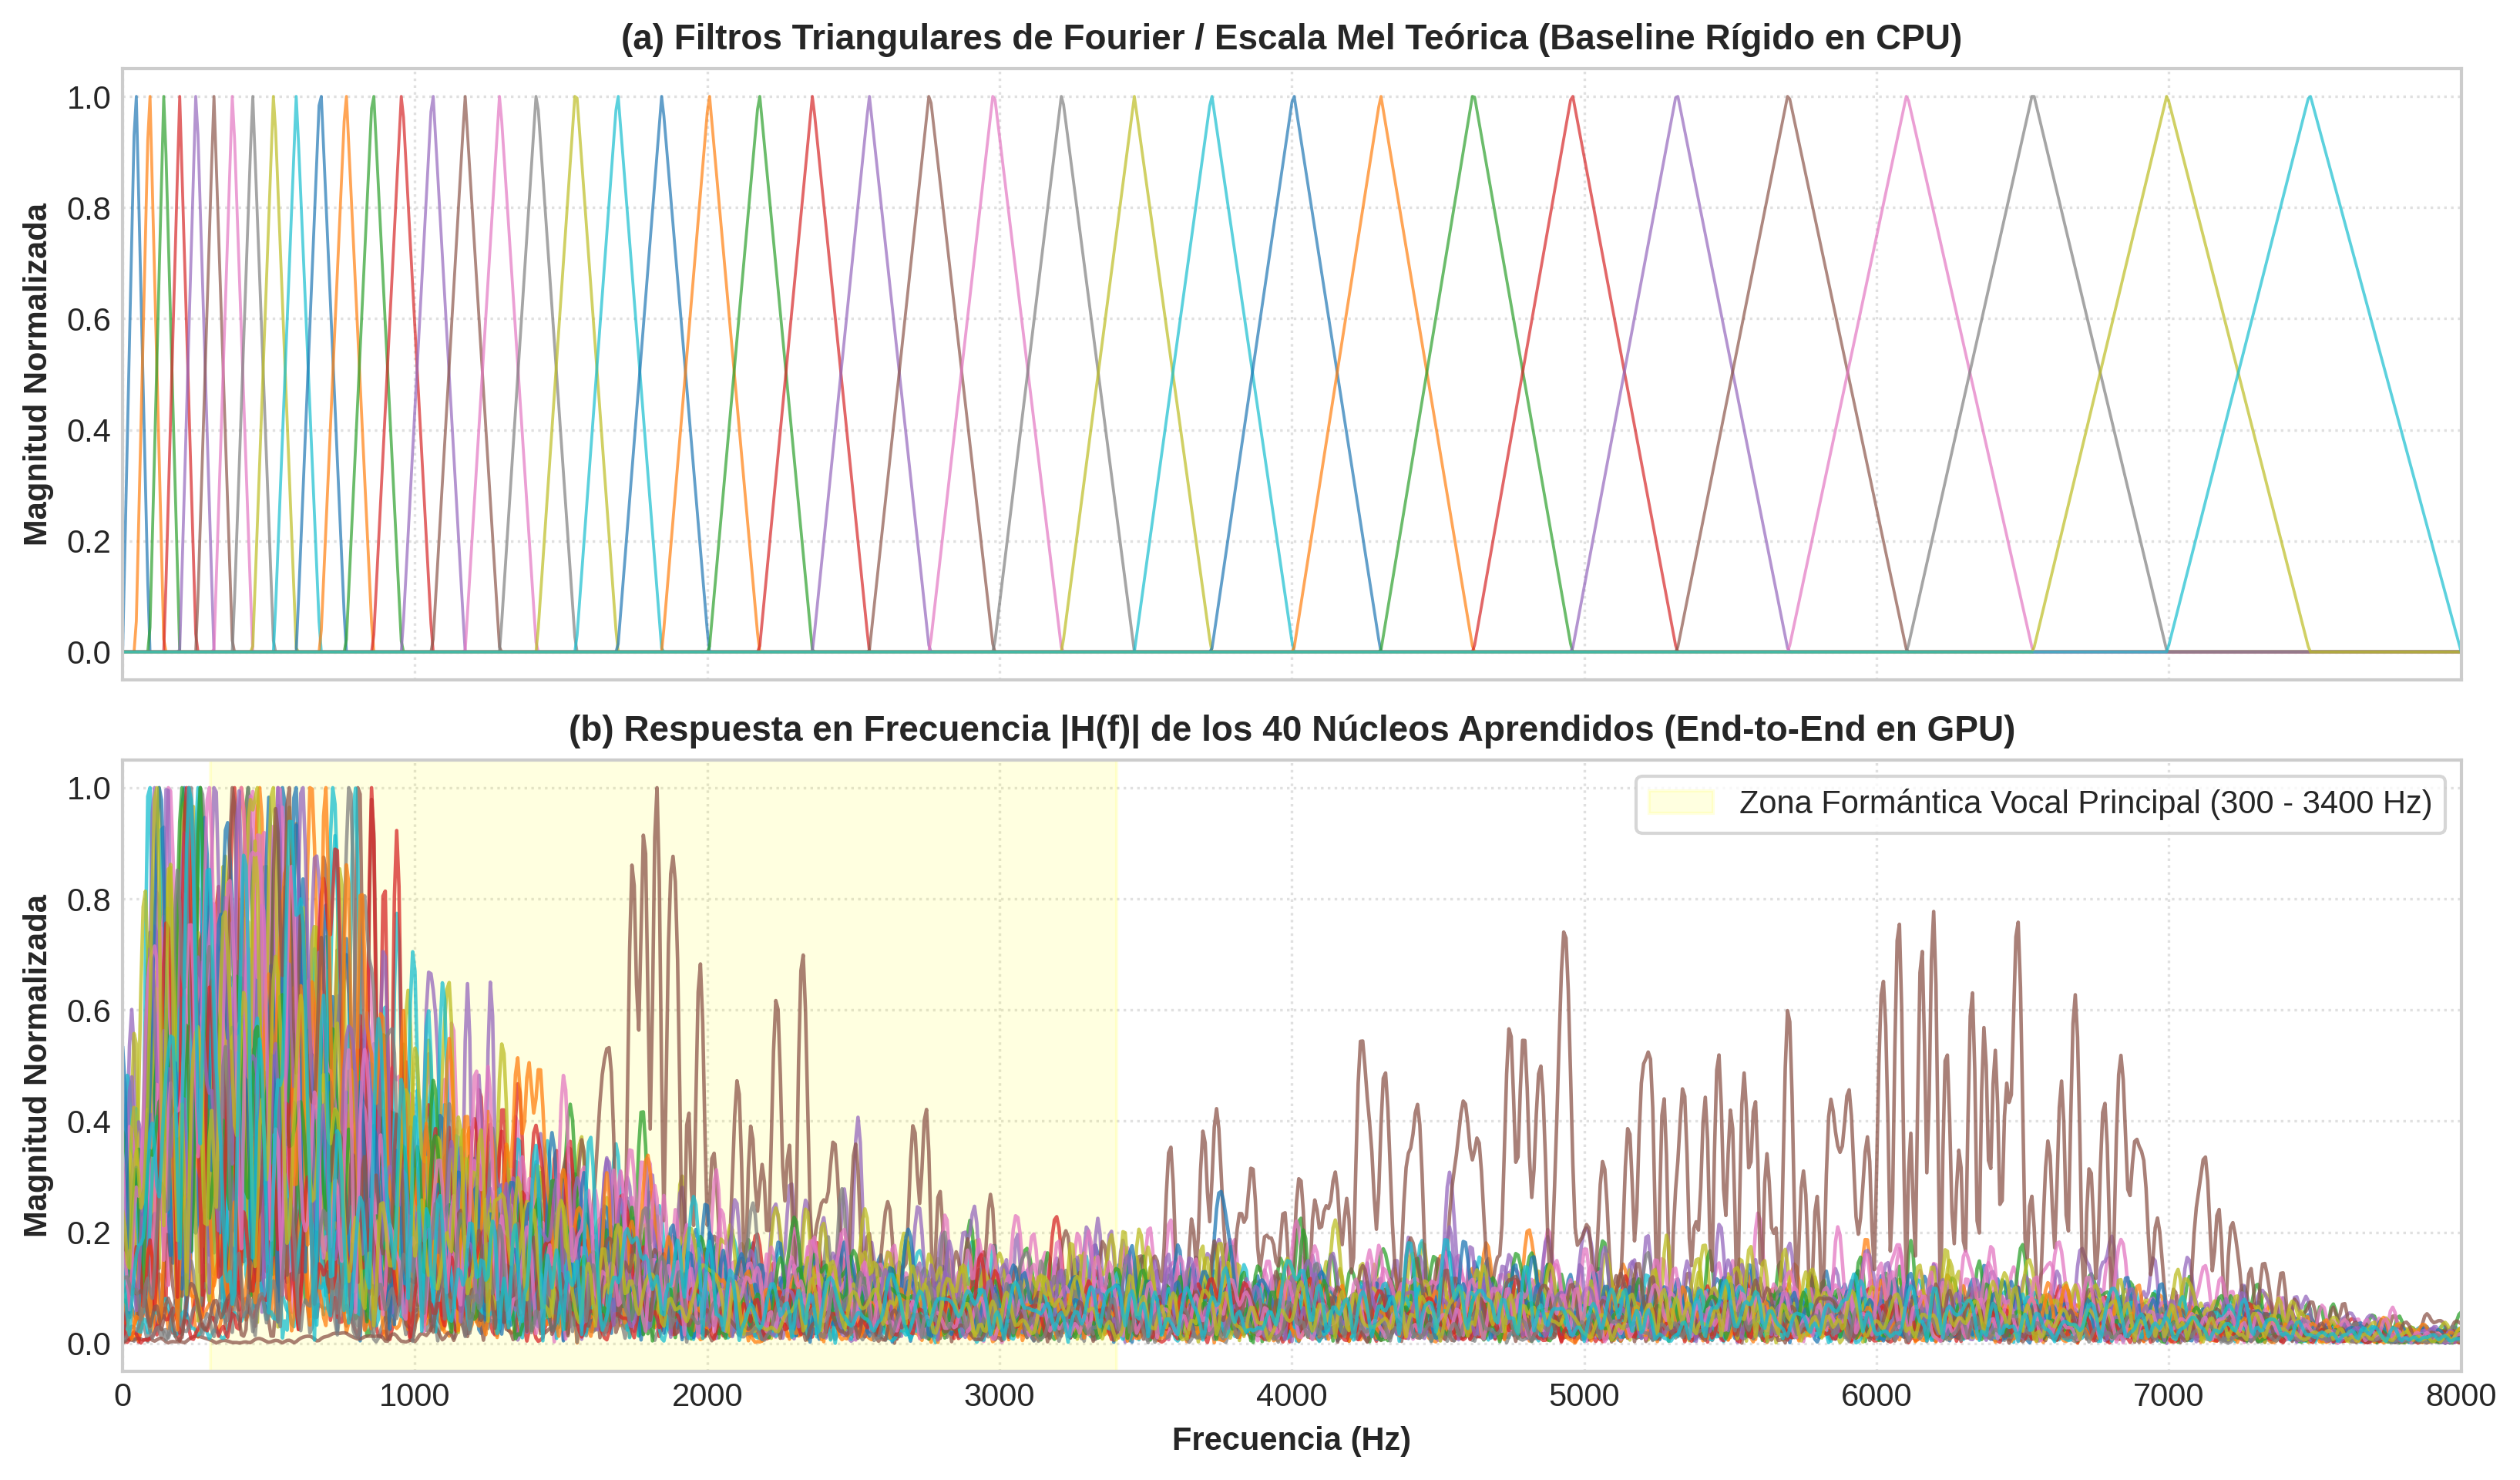

✓ Gráfico de interpretabilidad guardado en 'figura_interpretacion_filtros_fft.png'


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchaudio.functional as aF

#extraer los 40 nucleos temporales entrenados de la primera capa
# dimensiones originales del tensor: [40, 1, 480]
weights = model_raw.front_end.weight.detach().cpu().squeeze(1).numpy()

num_filters, kernel_size = weights.shape
fs = 16000
n_fft = 2048  #interpolacion espectral de alta resolucion

#calculo de respuesta en frecuenciacon FFT
freqs = np.fft.rfftfreq(n_fft, d=1.0/fs)
fft_magnitudes = np.abs(np.fft.rfft(weights, n=n_fft, axis=-1))

#norm c filtro a [0, 1] para comparar visualmente
fft_norm = fft_magnitudes / (np.max(fft_magnitudes, axis=-1, keepdims=True) + 1e-8)

#Construir banco de filtros Mel de control (teoricos) (40 filtros)
mel_fb = aF.melscale_fbanks(
    n_freqs=n_fft // 2 + 1,
    f_min=0.0,
    f_max=fs / 2.0,
    n_mels=40,
    sample_rate=fs,
    norm="slaney"
).cpu().numpy()
mel_fb_norm = mel_fb / (np.max(mel_fb, axis=0, keepdims=True) + 1e-8)

#graficar comparativa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), dpi=300, sharex=True)

# Subgrafico superior: Banco Mel rigido de Kim et al.
ax1.plot(freqs, mel_fb_norm, lw=0.9, alpha=0.7)
ax1.set_title("(a) Filtros Triangulares de Fourier / Escala Mel Teórica (Baseline Rígido en CPU)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Magnitud Normalizada", fontsize=10, fontweight='bold')
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subgrafico inferior: Filtros Convolucionales 1D aprendidos por SGD
ax2.plot(freqs, fft_norm.T, lw=1.1, alpha=0.75)
ax2.set_title("(b) Respuesta en Frecuencia |H(f)| de los 40 Núcleos Aprendidos (End-to-End en GPU)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Frecuencia (Hz)", fontsize=10, fontweight='bold')
ax2.set_ylabel("Magnitud Normalizada", fontsize=10, fontweight='bold')
ax2.set_xlim(0, 8000)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle=':', alpha=0.6)

# Destacar zonas formánticas de consonantes (0-4 kHz)
ax2.axvspan(300, 3400, color='yellow', alpha=0.12, label='Zona Formántica Vocal Principal (300 - 3400 Hz)')
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig("figura_interpretacion_filtros_fft.png", dpi=300)
plt.show()
print("✓ Gráfico de interpretabilidad guardado en 'figura_interpretacion_filtros_fft.png'")

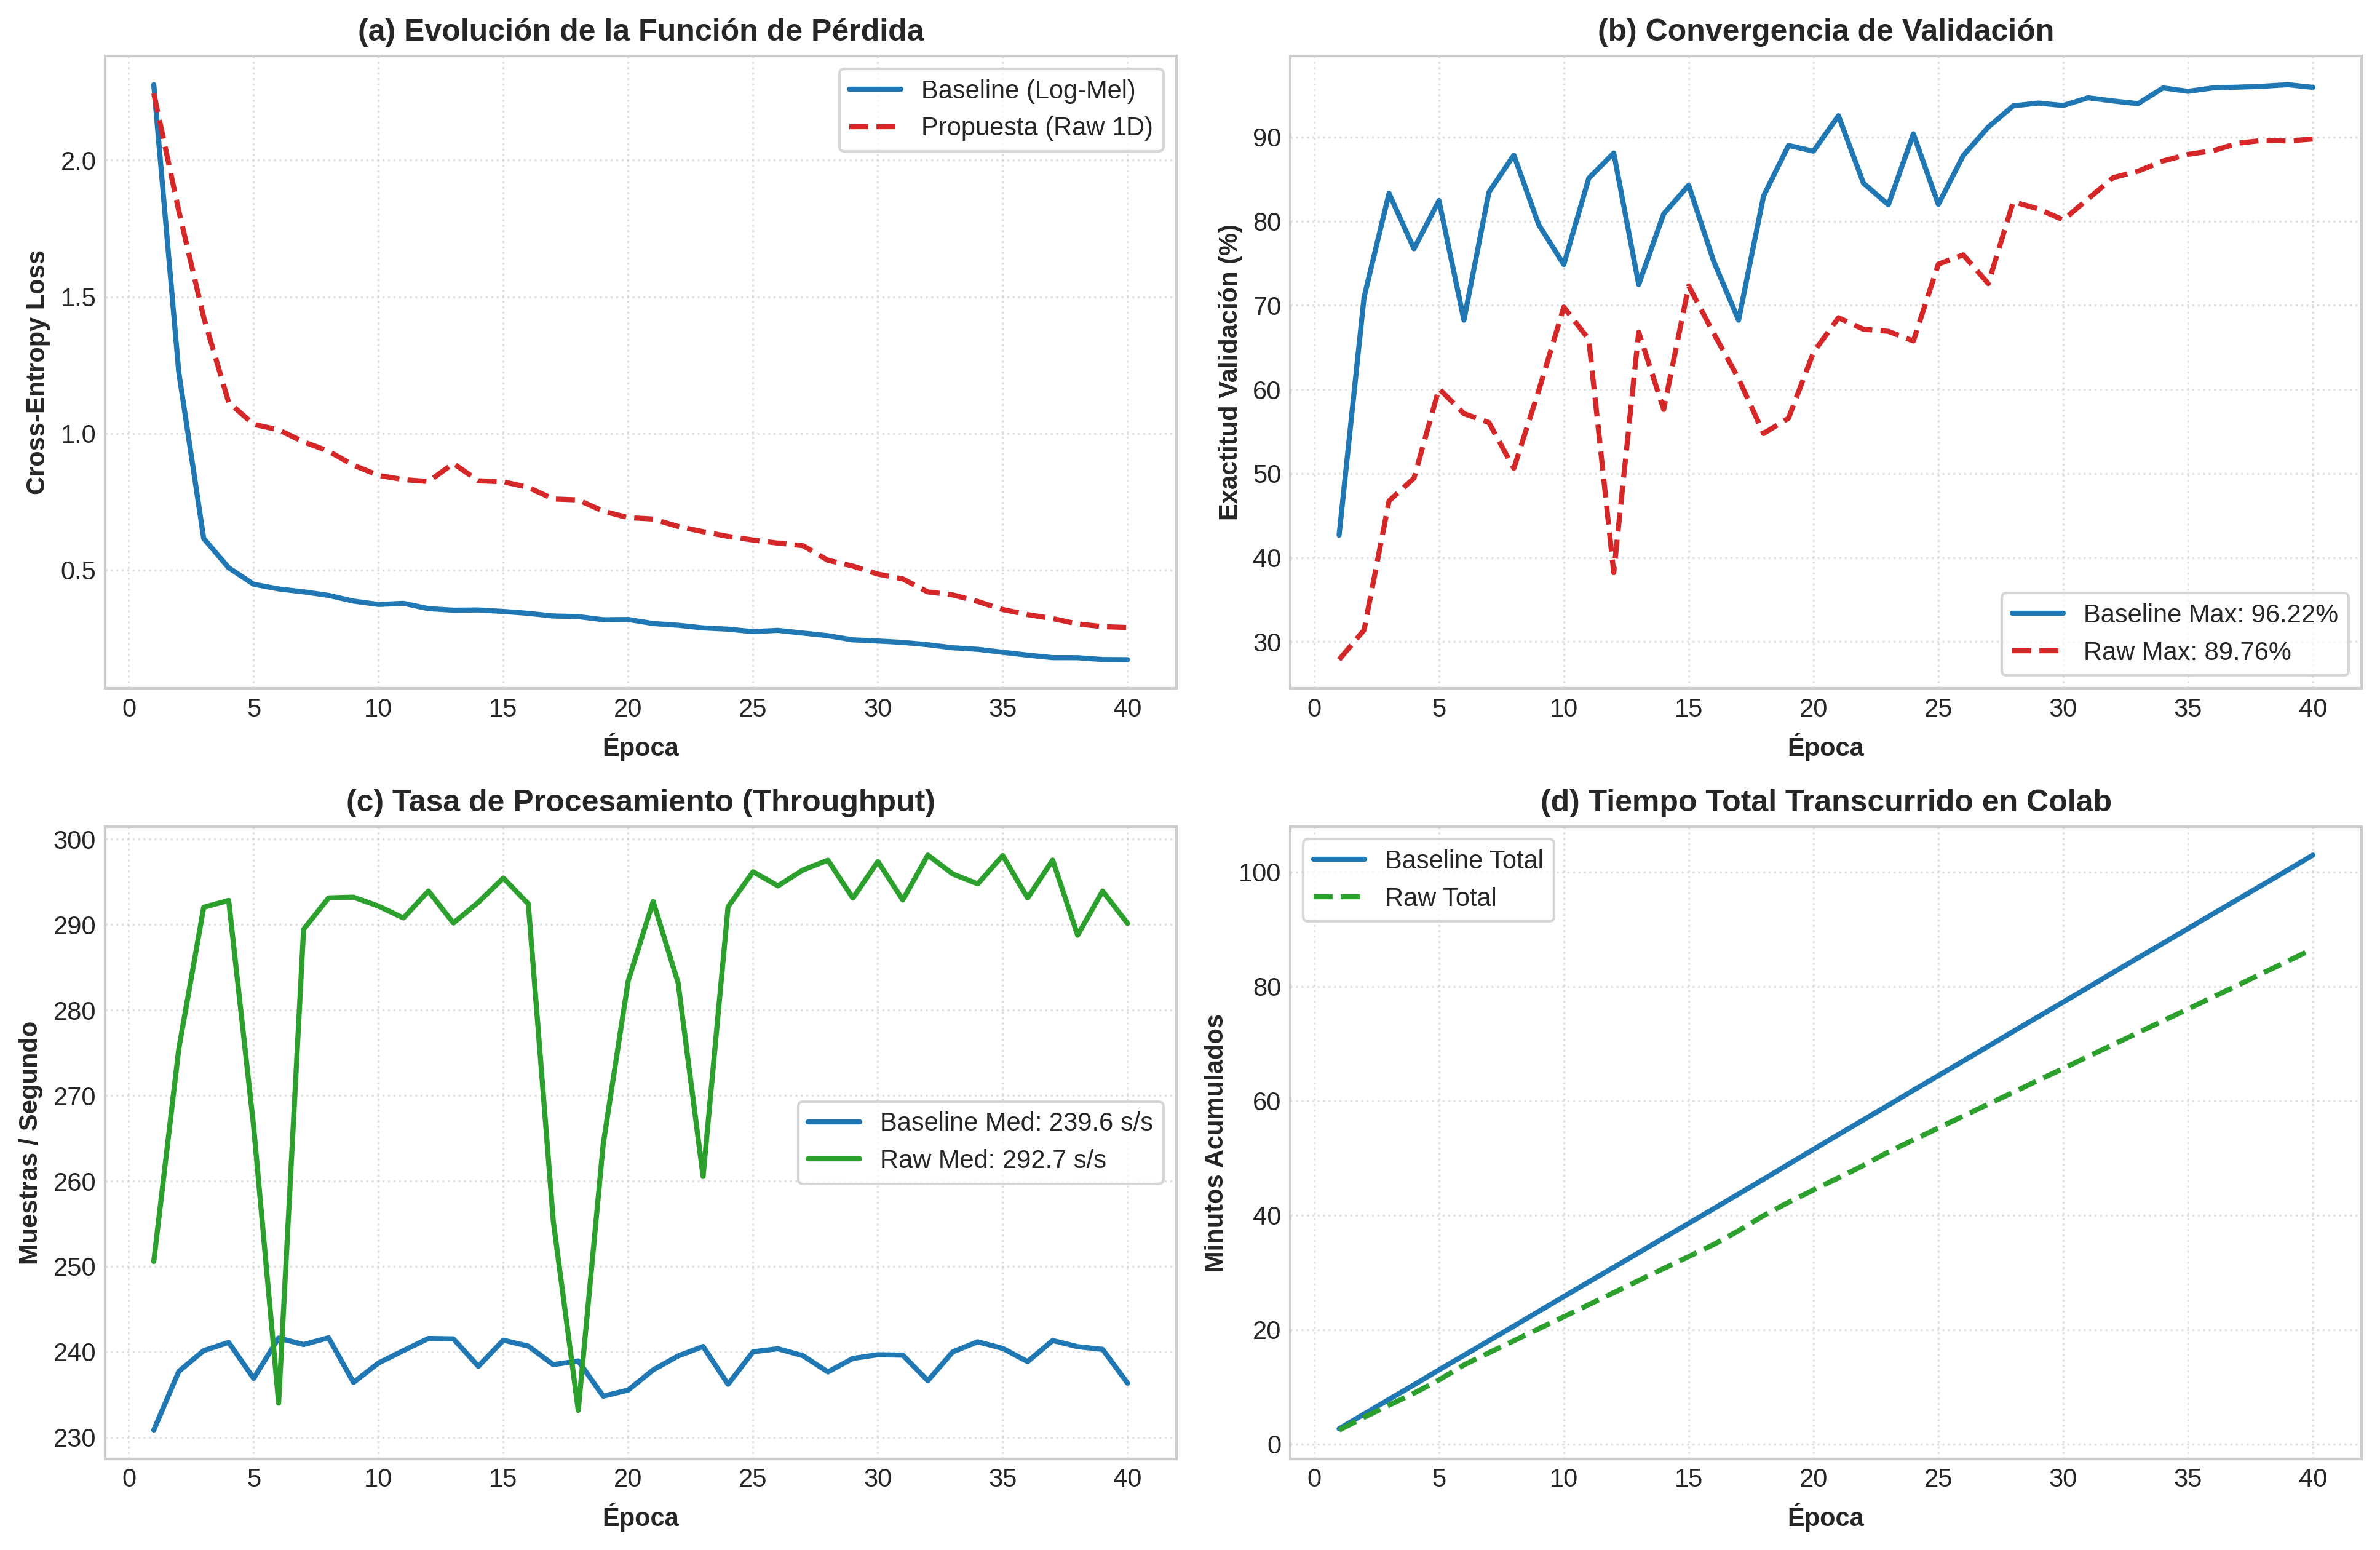

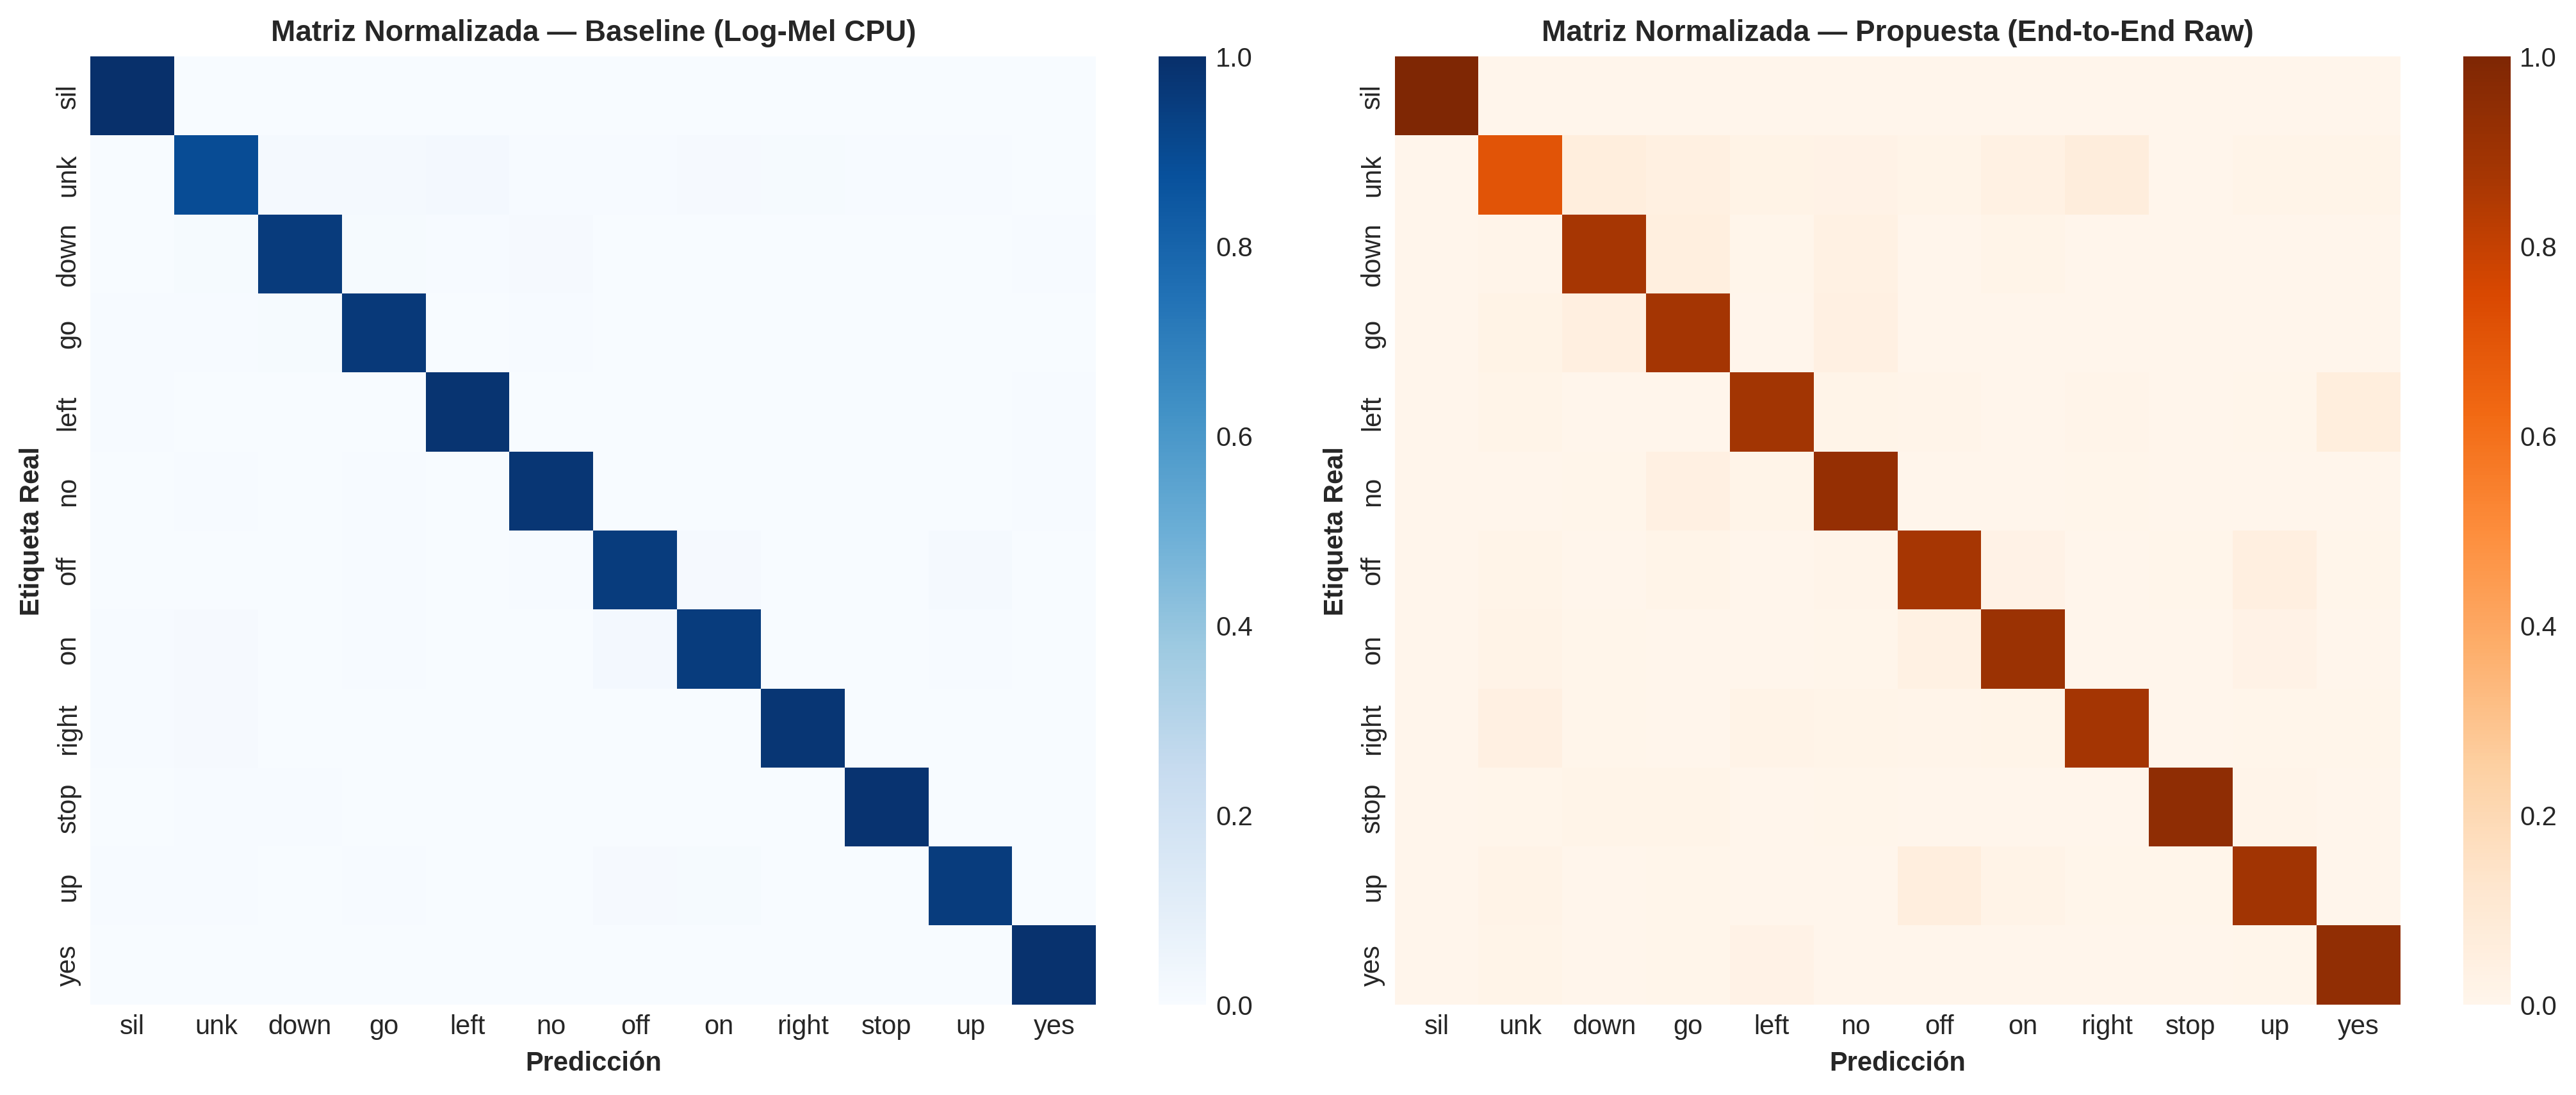

✓ Figuras 'figura_convergencia_comparativa.png' y 'figura_matrices_comparativas.png' generadas exitosamente.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar historiales de entrenamiento y matrices
df_raw = pd.read_csv("history_raw.csv")
df_base = pd.read_csv("history_baseline.csv")
matrices = np.load("matrices_confusion_comparativa.npy", allow_pickle=True).item()
labels_abrev = ['sil', 'unk', 'down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes']

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# FIGURA 1: Dinámica de Convergencia y Throughput
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(13, 8.5), dpi=300)

# (a) Pérdida de entrenamiento
ax1.plot(df_base['epoch'], df_base['train_loss'], label='Baseline (Log-Mel)', color='#1f77b4', lw=2)
ax1.plot(df_raw['epoch'], df_raw['train_loss'], label='Propuesta (Raw 1D)', color='#d62728', lw=2, linestyle='--')
ax1.set_xlabel('Época', fontweight='bold')
ax1.set_ylabel('Cross-Entropy Loss', fontweight='bold')
ax1.set_title('(a) Evolución de la Función de Pérdida', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True)

# (b) Exactitud de validación
ax2.plot(df_base['epoch'], df_base['val_acc'], label=f"Baseline Max: {df_base['val_acc'].max():.2f}%", color='#1f77b4', lw=2)
ax2.plot(df_raw['epoch'], df_raw['val_acc'], label=f"Raw Max: {df_raw['val_acc'].max():.2f}%", color='#d62728', lw=2, linestyle='--')
ax2.set_xlabel('Época', fontweight='bold')
ax2.set_ylabel('Exactitud Validación (%)', fontweight='bold')
ax2.set_title('(b) Convergencia de Validación', fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, loc='lower right')

# (c) Tasa de procesamiento (Throughput)
ax3.plot(df_base['epoch'], df_base['throughput'], label=f"Baseline Med: {df_base['throughput'].median():.1f} s/s", color='#1f77b4', lw=2)
ax3.plot(df_raw['epoch'], df_raw['throughput'], label=f"Raw Med: {df_raw['throughput'].median():.1f} s/s", color='#2ca02c', lw=2)
ax3.set_xlabel('Época', fontweight='bold')
ax3.set_ylabel('Muestras / Segundo', fontweight='bold')
ax3.set_title('(c) Tasa de Procesamiento (Throughput)', fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(frameon=True)

# (d) Tiempo de reloj acumulado (Wall-Clock Time)
ax4.plot(df_base['epoch'], df_base['duration_sec'].cumsum() / 60.0, label='Baseline Total', color='#1f77b4', lw=2)
ax4.plot(df_raw['epoch'], df_raw['duration_sec'].cumsum() / 60.0, label='Raw Total', color='#2ca02c', lw=2, linestyle='--')
ax4.set_xlabel('Época', fontweight='bold')
ax4.set_ylabel('Minutos Acumulados', fontweight='bold')
ax4.set_title('(d) Tiempo Total Transcurrido en Colab', fontweight='bold')
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend(frameon=True)

plt.tight_layout()
plt.savefig("figura_convergencia_comparativa.png", dpi=300)
plt.show()

# FIGURA 2: Matrices de Confusión Normalizadas
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 5.8), dpi=300)

cm_base = matrices['Baseline (Log-Mel CPU)'].astype('float') / matrices['Baseline (Log-Mel CPU)'].sum(axis=1)[:, np.newaxis]
cm_raw  = matrices['Propuesta (Raw Audio GPU)'].astype('float') / matrices['Propuesta (Raw Audio GPU)'].sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_base, ax=ax_a, cmap='Blues', annot=False, xticklabels=labels_abrev, yticklabels=labels_abrev)
ax_a.set_title("Matriz Normalizada — Baseline (Log-Mel CPU)", fontweight='bold', fontsize=11)
ax_a.set_xlabel("Predicción", fontweight='bold')
ax_a.set_ylabel("Etiqueta Real", fontweight='bold')

sns.heatmap(cm_raw, ax=ax_b, cmap='Oranges', annot=False, xticklabels=labels_abrev, yticklabels=labels_abrev)
ax_b.set_title("Matriz Normalizada — Propuesta (End-to-End Raw)", fontweight='bold', fontsize=11)
ax_b.set_xlabel("Predicción", fontweight='bold')
ax_b.set_ylabel("Etiqueta Real", fontweight='bold')

plt.tight_layout()
plt.savefig("figura_matrices_comparativas.png", dpi=300)
plt.show()
print("✓ Figuras 'figura_convergencia_comparativa.png' y 'figura_matrices_comparativas.png' generadas exitosamente.")